# **End to End Email spam identification**

# **Stage 1: Getting the data ready and EDA (Exploaratory data analysis)**

## You don't need to download the test data manually from Hugging Face. We can download both the training and testing datasets directly into your Jupyter Notebook using Python.

## The dataset already has two splits:
### - Training data: 8,175 messages.
### - Testing data: 2,725 messages.
#### We'll preserve the provided test split so that we can evaluate how well our deep learning model performs on data it has not trained on.

### One limitation to keep in mind: the dataset card says some legitimate messages are public forum posts and the spam examples may be synthetic. We'll use it to learn the workflow, but strong test performance won't automatically mean the model can detect every real-world email scam.

In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.15 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:12:53) [MSC v.1942 64 bit (AMD64)]
Python executable: C:\Users\HP\miniconda3\envs\dog-vision\python.exe


In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### **1) Check whether the datasets library is installed**

In [3]:
# import datasets

# print("Datasets library version:", datasets.__version__)

### **2) Install the dataset library**

In [4]:
# %pip install datasets

In [5]:
import datasets

print("Datasets library version:", datasets.__version__)

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Datasets library version: 5.1.0


### **3) Load our dataset**

In [1]:
from datasets import load_dataset

# Load the email spam dataset
email_dataset = load_dataset("diegovelilla/email-classification-dataset")

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


### **4) Examine the dataset structure**

In [7]:
print(email_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8175
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2725
    })
})


### **DatasetDict is a Hugging Face object that holds multiple dataset splits together. We can access each split separately:**

In [8]:
train_data = email_dataset["train"]

test_data = email_dataset["test"]

### **5) Check the first five training examples**

In [9]:
for i in range(5):
    print("Text:", train_data[i]["text"])
    print("Label:", train_data[i]["label"])
    print("-" * 80)

Text: hey I am looking for Xray baggage datasets can you provide me with the same 
Label: not_spam
--------------------------------------------------------------------------------
Text: "Get rich quick! Make millions in just days with our new and revolutionary system! Don't miss out on this amazing opportunity!"


Label: spam
--------------------------------------------------------------------------------
Text: URGENT MESSAGE: YOU WON'T BELIEVE WHAT WE HAVE TO OFFER!!!

Hey you! Yeah, you with the eyes reading this right now. Do you want to be the coolest cat on the block? Do you want to get all the likes, hearts and emojis? Do you want to be ~*POPULAR*~? Well, we have the solution for you.

Introducing our brand new feature that will blow your mind and your feed! We can't give away too many details, but let's just say it involves puppies, unicorns, and a drum kit.

But wait, there's more! Sign up
Label: spam
-----------------------------------------------------------------------------

### **Understanding the examples**
#### The labels are strings (words), not numbers.

#### This is important because our neural network will eventually need numerical representations of the text and labels.

#### The dataset contains different kinds of text, including:
#### - Promotional messages.
#### - Questions and requests.
#### - Articles and information.
#### - Other general written content.
#### This is useful for learning text classification. However, remember that the dataset documentation warns that some legitimate examples are public forum posts and the spam examples may be synthetic. Therefore, our model's performance may not directly represent performance on real-world email inboxes.

### **6) Check the distribution of our labels**

In [10]:
from collections import Counter

print("Training labels:")
print(Counter(train_data["label"]))

print("\nTesting labels:")
print(Counter(test_data["label"]))

Training labels:
Counter({'spam': 4125, 'not_spam': 4050})

Testing labels:
Counter({'spam': 1375, 'not_spam': 1350})


#### **Our training and testing datasets are both almost perfectly balanced. The difference between the two categories is very small.**

#### A **`balanced`** dataset means that the different classes have approximately equal numbers of examples.

#### In our case:
#### - Training data: 4,125 spam vs. 4,050 not spam.
#### - Testing data: 1,375 spam vs. 1,350 not spam.
#### This is good because our model will have a reasonable number of examples from both categories to learn from.

### **7) Examine the length of the text**
#### Unlike numerical datasets, text data can have different lengths.

In [11]:
# Get the length of each text in the training data
text_lengths = [len(text) for text in train_data["text"]]

# Display some statistics
print("Shortest text:", min(text_lengths))
print("Longest text:", max(text_lengths))
print("Average text length:", sum(text_lengths) / len(text_lengths))

Shortest text: 2
Longest text: 41544
Average text length: 369.11131498470945


### **Why is this important for deep learning?**
#### Our neural network cannot directly understand raw text. We must convert the text into numbers.

#### One way to do this is through tokenization.

#### Tokenization means breaking text into smaller units called tokens. These can be words or parts of words.

#### For example:
#### Original text: "Get rich quick! Make millions today."

#### After tokenization: `Get` `rich` `quick!` `Make` `millions` `today.`

### **8) One more investigation before preprocessing**
#### I want us to understand how the text lengths are distributed, rather than relying only on the average.

#### **Let's calculate the median and a few percentiles.**

In [12]:
import numpy as np

print("25th percentile:", np.percentile(text_lengths, 25))
print("50th percentile (Median):", np.percentile(text_lengths, 50))
print("75th percentile:", np.percentile(text_lengths, 75))
print("95th percentile:", np.percentile(text_lengths, 95))
print("99th percentile:", np.percentile(text_lengths, 99))

25th percentile: 175.0
50th percentile (Median): 284.0
75th percentile: 507.0
95th percentile: 760.0
99th percentile: 1486.7200000000048


#### **Understanding the percentiles**

In [13]:
import pandas as pd

percentile_results = pd.DataFrame({
    "Percentile": ["25th", "50th (Median)", "75th", "95th", "99th"],
    "Characters": [
        np.percentile(text_lengths, 25),
        np.percentile(text_lengths, 50),
        np.percentile(text_lengths, 75),
        np.percentile(text_lengths, 95),
        np.percentile(text_lengths, 99)
    ],
    "Meaning": [
        "25% of texts have 175 characters or fewer.",
        "50% of texts have 284 characters or fewer.",
        "75% of texts have 507 characters or fewer.",
        "95% of texts have 760 characters or fewer.",
        "99% of texts have approximately 1,487 characters or fewer."
    ]
})

percentile_results

,Percentile,Characters,Meaning
0,25th,175.00,25% of texts have 175 characters or fewer.
1,50th (Median),284.00,50% of texts have 284 characters or fewer.
2,75th,507.00,75% of texts have 507 characters or fewer.
3,95th,760.00,95% of texts have 760 characters or fewer.
4,99th,1486.72,"99% of texts have approximately 1,487 characte..."


#### Although our longest text contains 41,544 characters, 99% of the training texts are approximately 1,487 characters or shorter.

#### This means we have a few extremely long texts that could affect our preprocessing decisions.

#### **What is the median, and why is it useful?**
#### The median is the middle value when all observations are arranged in ascending order.

#### Our median is 284 characters. This means half of our training texts contain 284 characters or fewer, while the other half contain at least 284 characters.

#### Unlike the mean (369), the median is less affected by extremely long texts.

### **8) Let's visualise the distribution**
#### Before deciding how many tokens our model should accept, let's see the distribution.

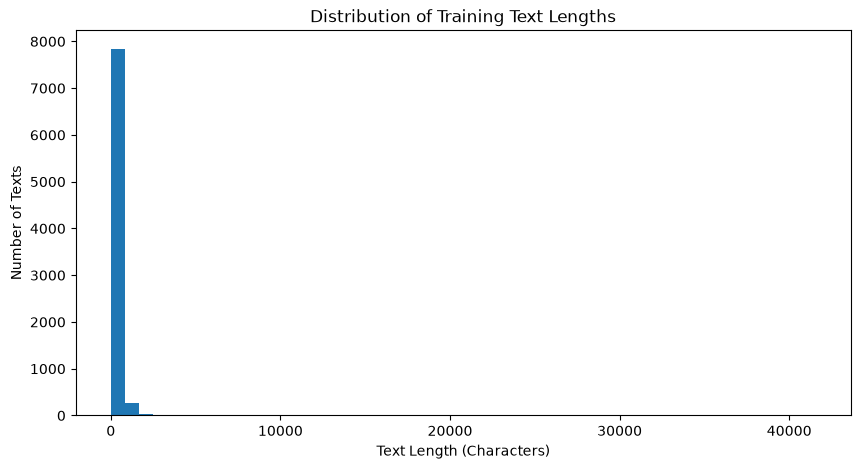

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(text_lengths, bins=50)

plt.xlabel("Text Length (Characters)")
plt.ylabel("Number of Texts")
plt.title("Distribution of Training Text Lengths")

plt.show()

#### **From the graph:**
#### - Most of the texts are concentrated on the left.
#### - A small number of texts are much longer.
#### - The longest text has 41,544 characters.
#### - These extremely long texts stretch the horizontal axis, making the shorter texts difficult to distinguish.
#### This explains why almost all the bars appear squeezed together.

#### **Let's improve the graph**

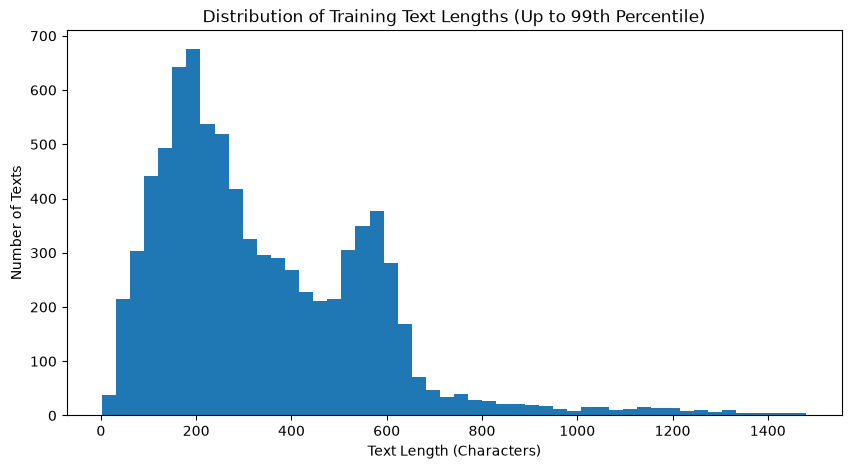

In [15]:
import matplotlib.pyplot as plt

# Get the 99th percentile
percentile_99 = np.percentile(text_lengths, 99)

# Keep texts within the 99th percentile for visualisation
text_lengths_99 = [
    length for length in text_lengths
    if length <= percentile_99
]

# Plot the distribution
plt.figure(figsize=(10, 5))

plt.hist(text_lengths_99, bins=50)

plt.xlabel("Text Length (Characters)")
plt.ylabel("Number of Texts")
plt.title("Distribution of Training Text Lengths (Up to 99th Percentile)")

plt.show()

#### The tallest bars are around 175–220 characters. This means a large number of our texts fall within that range.

### **I notice three things:**
#### **1.** Most texts are relatively short: A large concentration occurs between approximately 100 and 400 characters.
#### **2.** Another concentration appears around 500–600 characters: This suggests that we have another group of longer texts.
#### **3.** The distribution has a long right tail: As text length increases beyond approximately 650 characters, the number of texts generally decreases.
#### The distribution is therefore right-skewed, with some variation in the lengths of the messages.

### **Why is this important to our model?**
#### Remember that neural networks work with numerical data, not raw text.

#### When we eventually convert our messages into numerical sequences, we need to decide how many tokens the model should process for each message.

### **For example, if we choose a maximum sequence length of 200 tokens:**
#### - Messages shorter than 200 tokens will be padded.
#### - Messages longer than 200 tokens will be truncated.
#### We don't want to choose this length carelessly because we could lose useful information.

# **Stage 2: Text preprocessing and tokenization**

### B4 we continue to writing a code, let's understand what we want to achieve.

#### Our dataset currently contains text such as:**`"Get rich quick! Make millions in just days!"`**

#### A neural network cannot directly understand these words. We need to convert them into numerical representations.

#### **Our preparation process will involve:**
#### **1. Tokenization:** Breaking text into smaller units called tokens.
#### **2. Vocabulary creation:** Building a collection of words the model recognises.
#### **3. Numerical conversion:** Assigning integer IDs to tokens.
#### **4. Padding and truncation:** Making sequences suitable for batch processing.
#### We'll use TensorFlow's TextVectorization layer to do this.

### **1) Prepare the training text**
#### First, let's extract the text column from our training dataset.

In [16]:
# Extract the text from the training dataset
train_texts = train_data["text"]

# Check the number of training texts
print("Number of training texts:", len(train_texts))

# Display the first training text
print("\nFirst training text:")
print(train_texts[0])

Number of training texts: 8175

First training text:
hey I am looking for Xray baggage datasets can you provide me with the same 


### **2) Create the TextVectorization layer**
#### We will use TensorFlow's TextVectorization layer.
#### **What is TextVectorization?** It is a TensorFlow layer that helps us convert text into numbers.

#### For example, consider this sentence: **`"I love machine learning"`**

#### After tokenization and numerical conversion, it might become: **`[4, 28, 15, 63]`**

#### Each number represents a token in the vocabulary created by the layer.

#### **Create the layer**

In [17]:
# Create the TextVectorization layer
text_vectorizer = tf.keras.layers.TextVectorization(
    # TextVectorization: creates the text-processing layer.
    max_tokens=10000, 
    # max_tokens=10000: limits the vocabulary to a maximum of 10,000 tokens, including reserved tokens.
    output_mode="int"
    # output_mode="int": tells TensorFlow to represent each token using an integer ID.
    
)

### **3) Let the layer learn the vocabulary**

In [18]:
text_vectorizer.adapt(train_texts)

### **4) Examine the vocabulary**4) 
#### Remember, a vocabulary is the collection of tokens (words) that our model can recognise.

In [19]:
# Get the vocabulary learned by TextVectorization
vocabulary = text_vectorizer.get_vocabulary()
# get_vocabulary() retrieves all the tokens learned by our TextVectorization layer.

# Check the vocabulary size
print("Vocabulary size:", len(vocabulary))

# Display the first 20 tokens
print("\nFirst 20 tokens:")
print(vocabulary[:20])

Vocabulary size: 10000

First 20 tokens:
['', '[UNK]', np.str_('the'), np.str_('to'), np.str_('and'), np.str_('a'), np.str_('you'), np.str_('of'), np.str_('for'), np.str_('i'), np.str_('on'), np.str_('in'), np.str_('your'), np.str_('our'), np.str_('with'), np.str_('that'), np.str_('is'), np.str_('this'), np.str_('data'), np.str_('have')]


In [20]:
import pandas as pd

special_tokens = pd.DataFrame({
    "Index": [0, 1, 2, 3, 4, 5],
    "Token": ["''", "[UNK]", "the", "to", "and", "a"],
    "Meaning": [
        "Padding token",
        "Unknown token",
        "A recognised word",
        "A recognised word",
        "A recognised word",
        "A recognised word"
    ]
})

special_tokens

,Index,Token,Meaning
0,0,'',Padding token
1,1,[UNK],Unknown token
2,2,the,A recognised word
3,3,to,A recognised word
4,4,and,A recognised word
5,5,a,A recognised word


#### **Why are the most common words appearing first?**

#### TextVectorization generally orders the vocabulary by frequency, with more frequent tokens appearing earlier.

#### For example, `the` appears frequently in English text, which explains why it has a low index.

#### Also, np.str_('the') is simply NumPy's string representation. It is not an error.

### **5) Let's see how words become numbers**

In [21]:
# Select the first training message
sample_text = train_texts[0]

# Convert the text into numerical tokens
sample_vector = text_vectorizer(sample_text)

print("Original text:")
print(sample_text)

print("\nNumerical representation:")
print(sample_vector.numpy())
# .numpy() displays the resulting TensorFlow tensor as a NumPy array.

Original text:
hey I am looking for Xray baggage datasets can you provide me with the same 

Numerical representation:
[  97    9   60   38    8 4527    1   86   26    6  476   73   14    2
  275]


### **6) Let's verify the conversion ourselves using Pandas**
#### Rather than guessing what every number represents, let's ask TensorFlow's vocabulary to show us.

In [22]:
# Get the numerical IDs
token_ids = sample_vector.numpy() # We retrieve the numerical IDs generated by our vectorizer.

# Convert each numerical ID back to its token
sample_tokens = [] # We create an empty list and loop through each numerical ID.

for token_id in token_ids:
    # For every ID, we use it as an index to retrieve the corresponding word from our vocabulary.
    sample_tokens.append(vocabulary[token_id])
# For example, if the ID is 97, vocabulary[97] retrieves the token at index 97.

# Create a DataFrame: We use Pandas to display the numerical IDs alongside their corresponding tokens.
token_mapping = pd.DataFrame({
    "Token ID": token_ids,
    "Token": sample_tokens
})

token_mapping

,Token ID,Token
0,97,hey
1,9,i
2,60,am
3,38,looking
4,8,for
5,4527,xray
6,1,[UNK]
7,86,datasets
8,26,can
9,6,you


#### One interesting observation: Xray has been converted to xray and assigned ID 4527. The following word, baggage, was not in the vocabulary, so it became [UNK] (ID 1).

#### Something important to understand
#### Our model does not understand these numbers as ordinary mathematical values. For example, `4527` is not greater or more important than `97.`

#### They are simply identifiers assigned to tokens in the vocabulary.

### **7) Padding and truncation** 

#### Currently, our messages have different lengths.

#### **For example:**
#### - Message A might contain 15 tokens.
#### - Message B might contain 30 tokens.
#### - Message C might contain 100 tokens.
#### Neural networks generally need sequences in a batch to have the same length.

#### **We therefore use:**
#### - **Padding:** Adding zeros to shorter sequences.
#### - **Truncation:** Removing tokens from sequences that exceed our chosen maximum length.

#### **Let's see how many tokens our training messages contain**

In [23]:
# Calculate the number of tokens in each training message
sequence_lengths = [len(text_vectorizer(text)) for text in train_texts]

print(f"Shortest sequence:, {min(sequence_lengths)} tokens")
print(f"Longest sequence:, {max(sequence_lengths)} tokens")
print(f"Average sequence length:, {np.mean(sequence_lengths)} tokens")

Shortest sequence:, 0 tokens
Longest sequence:, 791 tokens
Average sequence length:, 59.58226299694189 tokens


#### Notice that the average sequence length is approximately 60 tokens, while the longest sequence contains 791 tokens.

#### This means most messages are relatively short, but some are considerably longer.

#### **Why is the shortest sequence zero?**
#### This is something worth investigating.

#### A sequence of zero means that at least one message produced no recognised tokens.

#### **Possible reasons include:**
#### - The message is empty.
#### - It contains only punctuation or characters that the vectorizer removes during standardisation.

#### **Let's run the below to find the messages that produces 0 tokens**

In [24]:
# Find the training messages that produce zero tokens
empty_indices = [
    i for i, text in enumerate(train_texts) # enumerate() gives us both the position and the message.
    if len(text_vectorizer(text)) == 0
]
# empty_indices stores the positions of messages that produce zero tokens.

print("Number of empty sequences:", len(empty_indices))

# Display the original messages
for i in empty_indices[:10]:
    print(f"Index: {i}")
    print(f"Text: {repr(train_texts[i])}")
    print("-" * 50)

Number of empty sequences: 1
Index: 1569
Text: '^^'
--------------------------------------------------


#### It contains only two caret symbols (^). Your TextVectorization layer removes punctuation during its standardisation process. Since there are no actual words left after removing those symbols, the result is an empty sequence.

In [25]:
print("Message:", repr(train_texts[1569]))
print("Label:", train_data[1569]["label"])

Message: '^^'
Label: not_spam


#### Let's remove rthe double caret since it contains no useful message. so we will remove both test and corressponding label.
#### Let's first create a list of training labels and remove the sample from both lists.

In [26]:
# Extract the training labels
train_labels = train_data["label"]

# Remove the empty sequence from the training texts and labels
train_texts = [
    text for i, text in enumerate(train_texts)
    if i not in empty_indices
]

train_labels = [
    label for i, label in enumerate(train_labels)
    if i not in empty_indices
]

print("Number of training texts:", len(train_texts))
print("Number of training labels:", len(train_labels))

Number of training texts: 8174
Number of training labels: 8174


### **8) Examine the token sequence lengths**
#### Remember, earlier we found:
#### - Shortest sequence: 0
#### - Longest sequence: 791
#### - Average sequence length: approximately 59.58
#### Those figures were calculated before removing the empty sequence. Let's recalculate them using our cleaned training texts.

In [27]:
# Calculate the number of tokens in each training message
sequence_lengths = [
    len(text_vectorizer(text)) for text in train_texts
]

print(f"Shortest sequence:, {min(sequence_lengths)} tokens")
print(f"Longest sequence:, {max(sequence_lengths)} tokens")
print(f"Average sequence length:, {np.mean(sequence_lengths)} tokens")

Shortest sequence:, 1 tokens
Longest sequence:, 791 tokens
Average sequence length:, 59.58955223880597 tokens


#### **Why are we doing this?**
#### We need to decide how many tokens the model should receive for each message.
#### For example, if we choose a maximum sequence length of 100:
#### - Messages with fewer than 100 tokens will need padding.
#### - Messages with more than 100 tokens will be truncated.

#### **What should we use as the maximum sequence length?**
#### We shouldn't automatically choose 60 just because the average is approximately 60.

#### For example, some messages may contain 200, 300 or even 700 tokens. If we choose 60, we could lose important information from longer messages.

#### Let's examine the percentiles first.

In [28]:
# Calculate important sequence-length percentiles
sequence_percentiles = pd.DataFrame({
    "Percentile": ["25th", "50th (Median)", "75th", "90th", "95th", "99th"],
    "Token Count": [
        np.percentile(sequence_lengths, 25),
        np.percentile(sequence_lengths, 50),
        np.percentile(sequence_lengths, 75),
        np.percentile(sequence_lengths, 90),
        np.percentile(sequence_lengths, 95),
        np.percentile(sequence_lengths, 99)
    ]
})

sequence_percentiles

,Percentile,Token Count
0,25th,30.0
1,50th (Median),47.0
2,75th,86.0
3,90th,105.0
4,95th,116.0
5,99th,212.0


#### Notice something interesting: the average is approximately 60 tokens, but the median is 47. This happens because some longer messages pull the average upwards.

#### **Choosing our sequence length**
#### I suggest we start with 120 tokens.

#### **Why?**
#### - The 95th percentile is 116 tokens.
#### - A sequence length of 120 should accommodate approximately 95% of our messages without truncation.
#### - Longer messages will be truncated to 120 tokens.
#### - Shorter messages will be padded with zeros.

#### **Next, we'll configure our TextVectorization layer with output_sequence_length=120. This means every message will be converted into exactly 120 positions.**

### **9) Update the TextVectorization layer**

In [29]:
text_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=120 # This is what is difft from the initial TextVectorization layer
    #  we created
)

# Adapt the vectorizer using training texts only
text_vectorizer.adapt(train_texts)

#### **output_sequence_length=120** tells TensorFlow to return exactly 120 token positions for every message.
#### - If a message has 40 tokens, TensorFlow adds 80 padding zeros.
#### - If a message has 120 tokens, nothing needs to be added or removed.
#### - If a message has 200 tokens, TensorFlow truncates it to 120.

### **10) Test the new vectorizer**

In [30]:
# Convert one training message into numerical form
sample_vector = text_vectorizer(train_texts[0])

print("Shape:", sample_vector.shape)
print("Number of tokens:", len(sample_vector))
print("Numerical representation:")
print(sample_vector.numpy())

Shape: (120,)
Number of tokens: 120
Numerical representation:
[  97    9   60   38    8 4527    1   86   26    6  476   73   14    2
  275    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


### **Let's verify this with another message**
#### I want us to check a longer message too, so we can understand how the vectorizer handles sequences of different lengths.

In [31]:
# Find the longest message in the training data
longest_index = np.argmax(sequence_lengths)

longest_text = train_texts[longest_index]

# Convert it into numerical form
longest_vector = text_vectorizer(longest_text)

print("Original token count:", sequence_lengths[longest_index])
print("Vector shape:", longest_vector.shape)
print("Number of non-zero tokens:", np.count_nonzero(longest_vector.numpy()))

Original token count: 791
Vector shape: (120,)
Number of non-zero tokens: 120


#### **An important point about truncation**
#### We have chosen 120 because it accommodates approximately 95% of our training messages. However, some longer messages will lose information.

#### **This is a trade-off:**
#### - A smaller sequence length means less computation and memory usage.
#### - A larger sequence length preserves more information but requires more computation and memory.
#### For our first model, we'll keep 120. We can experiment with a longer sequence length later to see whether it improves performance.

### **11) Convert our labels into numbers**
#### **Our messages are now represented numerically, but our labels are still strings:**
#### - spam
#### - not_spam
#### A neural network needs numerical targets for training.

#### **I suggest this mapping:**
#### - spam -> 1 (Numerical label)
#### - not_spam -> 0 (Numerical label)
#### This is known as  label **`encoding`**

#### **Let's first extract the training labels and examine their current values.**

In [32]:
# Display the first 10 training labels
print(train_labels[:10])

# Check the unique labels
print(set(train_labels))

['not_spam', 'spam', 'spam', 'not_spam', 'not_spam', 'not_spam', 'not_spam', 'not_spam', 'not_spam', 'spam']
{'spam', 'not_spam'}


#### **Convert the labels into numbers**
#### **Define the function that converts text into numbers**

In [33]:
def encode_labels(labels):
    """
    Converts spam and not_spam labels into numerical values.
    not_spam = 0
    spam = 1
    """
    label_mapping = {
        "not_spam": 0,
        "spam": 1
    }

    encoded_labels = np.array([
        label_mapping[label] for label in labels
    ])

    return encoded_labels

In [34]:
# Encode training and test labels
train_labels = encode_labels(train_data["label"])

print("Training labels:", train_labels[:10])
print("Training shape:", train_labels.shape)

Training labels: [0 1 1 0 0 0 0 0 0 1]
Training shape: (8175,)


### **12) Convert the test labels**
#### Remember, our test dataset still contains the original string labels. We need to convert them using the same mapping.

#### Why the same mapping? Because the model must interpret the numerical labels consistently during training and evaluation.

In [35]:
# Encode the test labels
test_labels = encode_labels(test_data["label"])

print("Test labels:", test_labels[:10])
print("Test shape:", test_labels.shape)

Test labels: [0 1 0 1 1 0 1 0 1 1]
Test shape: (2725,)


### **Let's verify that our training labels are also correct and that both sets contain only 0 and 1.**

In [36]:
print("Training labels shape:", train_labels.shape)
print("Test labels shape:", test_labels.shape)

print("Unique training labels:", np.unique(train_labels))
print("Unique test labels:", np.unique(test_labels))

Training labels shape: (8175,)
Test labels shape: (2725,)
Unique training labels: [0 1]
Unique test labels: [0 1]


### **13) Understand why we need a validation set**
#### **We already have two datasets:**
#### - Training data: 8,174 messages.
#### - Test data: 2,725 messages.
#### **We will divide the 8,174 training messages into two groups:**
#### **1. Training set:** Used by the model to learn patterns that distinguish spam from legitimate messages.
#### **2. Validation set:** Used to monitor how well the model performs on messages it has not trained on, while we develop and improve it.
#### We'll keep the 2,725 test messages untouched until final evaluation.

### **14) Split the training data**

In [37]:
# from sklearn.model_selection import train_test_split

# # Split training data into training and validation sets
# X_train, X_val, y_train, y_val = train_test_split(
#     train_texts, # Our cleaned training messages.
#     train_labels, # Their corresponding numerical labels.
#     test_size=0.2, # Reserves 20% for validation.
#     random_state=42, # Makes the split reproducible.
#     stratify=train_labels # Maintains approximately the same spam/not-spam proportions in both groups.
# )

# print("Training messages:", len(X_train))
# print("Validation messages:", len(X_val))
# print("Training labels:", len(y_train))
# print("Validation labels:", len(y_val))

### The above code will give error bcos we we removed one empty message ('^^') from train_texts, reducing it from 8,175 to 8,174. However, your train_labels still contains 8,175 labels. We must remove the corresponding label as well.

### **Correct the training labels**
### Rather than trying to remove the label from the already-converted array, let's rebuild the labels from the original dataset and use our existing encode_labels() function.

In [38]:
# Extract the original training labels
original_train_labels = train_data["label"]

# Remove the label corresponding to the empty message
cleaned_train_labels = [
    label for i, label in enumerate(original_train_labels)
    if i not in empty_indices
]

# Encode the cleaned labels
train_labels = encode_labels(cleaned_train_labels)

print("Training texts:", len(train_texts))
print("Training labels:", len(train_labels))

Training texts: 8174
Training labels: 8174


### **14) Split the training data**

In [39]:
from sklearn.model_selection import train_test_split

# Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    train_texts, # Our cleaned training messages.
    train_labels, # Their corresponding numerical labels.
    test_size=0.2, # Reserves 20% for validation.
    random_state=42, # Makes the split reproducible.
    stratify=train_labels # Maintains approximately the same spam/not-spam proportions in both groups.
)

print("Training messages:", len(X_train))
print("Validation messages:", len(X_val))
print("Training labels:", len(y_train))
print("Validation labels:", len(y_val))

Training messages: 6539
Validation messages: 1635
Training labels: 6539
Validation labels: 1635


### **15) Check the class distribution**
#### **Remember, our labels are:**
#### - 0 = not_spam
#### - 1 = spam
#### We used stratify=train_labels when splitting, but let's verify that the training and validation sets have similar class distributions.

In [40]:
# Check the distribution of labels in each dataset
print("Training set distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation set distribution:")
print(pd.Series(y_val).value_counts())

Training set distribution:
1    3300
0    3239
Name: count, dtype: int64

Validation set distribution:
1    825
0    810
Name: count, dtype: int64


### **16) Create TensorFlow datasets**
#### **Define the function to do the above**

In [41]:
def create_dataset(texts, labels):
    """
    Creates a TensorFlow dataset from text messages and labels.
    """
    dataset = tf.data.Dataset.from_tensor_slices(
        (texts, labels)
    )

    return dataset

#### **Use the function**

In [42]:
# Create training dataset
train_ds = create_dataset(X_train, y_train)

# Create validation dataset
val_ds = create_dataset(X_val, y_val)

# Create test dataset and convert the test tetxs to a list
test_ds = create_dataset(list(test_data["text"]), test_labels)

In [43]:
print("Training dataset:", train_ds)
print("Validation dataset:", val_ds)
print("Test dataset:", test_ds)

Training dataset: <_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>
Validation dataset: <_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>
Test dataset: <_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>


### **17) Inspect one example**

In [44]:
for text, label in train_ds.take(1): # take(1) retrieves just one example.
    # text.numpy() converts the TensorFlow string tensor into bytes.
    print("Email:", text.numpy().decode("utf-8"))
    # .decode("utf-8") converts those bytes into readable text.
    print("Label:", label.numpy()) # label.numpy() retrieves the numerical label.

Email: Working on a project app for school that would work okay without it - but it would save a ton of time if I could get a dataset (JSON/CSV/XML) of trivia questions with multiple choice answers, instead of writing them myself. 
Label: 0


### **18) Batch the datasets**
#### We'll use a batch size of 32, as we did in the image-classification projects.
#### **Why shuffle only the training dataset?**
#### We want the model to encounter training examples in a different order during each epoch. Validation and test datasets should remain in a consistent order because we use them to evaluate the model.

In [45]:
def prepare_dataset(dataset, batch_size=32, shuffle=False):
    # dataset: The TensorFlow dataset we want to prepare.
    # batch_size=32: Groups 32 messages together.
    # shuffle=False: Allows us to decide whether to randomise the order of examples.
    """
    Batches a TensorFlow dataset and prepares it for efficient processing.
    """

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=1000,
            # buffer_size=1000: When shuffling, TensorFlow uses a buffer of up to 1,000 examples.
            reshuffle_each_iteration=True
            # reshuffle_each_iteration=True: Randomises the order again for each training iteration.
        )

    dataset = dataset.batch(batch_size)
    # batch(32): Groups the examples into batches.

    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    # prefetch(tf.data.AUTOTUNE): Allows TensorFlow to prepare subsequent batches while the model 
    # processes the current one.

    return dataset

### **19) Create the three prepared datasets**

In [46]:
train_ds = prepare_dataset(train_ds, shuffle=True)
val_ds = prepare_dataset(val_ds)
test_ds = prepare_dataset(test_ds)

#### **Inspect the batches**

In [47]:
# Get one batch from the training dataset
for text_batch, label_batch in train_ds.take(1):

    print("Text batch shape:", text_batch.shape)
    print("Label batch shape:", label_batch.shape)

    print("\nFirst message:")
    print(text_batch[0].numpy().decode("utf-8"))

    print("\nFirst message label:")
    print(label_batch[0].numpy())

Text batch shape: (32,)
Label batch shape: (32,)

First message:
There is one dataset on kaggle which is from a Mexican website. Any dataset apart from that?

First message label:
0


### **20) Understand the model architecture**
### **Our model will use four main layers:**
#### **`1. Input layer:`** Receives the original email text.
#### **`2. TextVectorization:`** Converts words into numerical sequences of 120 tokens.
#### **`3. Embedding:`** Learns numerical representations of words so the model can capture useful patterns.
#### **`4. GlobalAveragePooling1D:`** Summarises the word representations into one representation for the message.
#### **`5. Dense output layer (Sigmoid):`** Produces a probability between 0 and 1 for spam classification.

#### **Why do we need an Embedding layer?**
#### **Computers do not naturally understand words such as:**
#### - congratulations, winner, meeting, tomorrow, money, offer
#### We have already used our TextVectorization layer to convert words into numbers.

#### For example, a message might become: [45, 12, 87, 231, 9, 0, 0, 0, ...]
#### Each number represents a word in our vocabulary. The zeros are padding.These numbers are only word IDs. They do not tell the model what the words mean.

#### **What does the Embedding layer do?**
#### The Embedding layer converts each word ID into a vector of learned numerical values.
#### Imagine we have: Word ID: 45
#### The Embedding layer might represent it with a vector like: [0.21, -0.34, 0.56, 0.12, -0.18, ...]
#### These numbers are learned during model training.

#### **What is the embedding dimension?**
#### tf.keras.layers.Embedding(
####    input_dim=10000, The maximum vocabulary size.
####    output_dim=16 Each word is represented by 16 learned numbers.
#### ) 

#### We chose a vocabulary size of 10,000 earlier when creating our TextVectorization layer.
#### The value 16 is a starting choice for our model. It is not a fixed rule; we can experiment with larger embedding dimensions later.

#### **What happens to the message?**
#### Remember that we set our sequence length to 120.

#### Therefore:
#### - Before Embedding: one message has 120 token IDs.
#### - After Embedding with output_dim=16: the message has 120 vectors, each containing 16 values.
#### Its shape changes from: `(120,)` to `(120, 16)`

### **21) Building our spam classification model**
#### **Import the libraries**

In [48]:
import tensorflow as tf
import numpy as np

#### **Define the model**

In [49]:
model = tf.keras.Sequential([

    # Input layer
    tf.keras.layers.Input(shape=(), dtype=tf.string),

    # Convert text into numerical sequences
    text_vectorizer,

    # Convert token IDs into learned word representations
    tf.keras.layers.Embedding(
        input_dim=10000, # vocabulary size.
        output_dim=16, # 16 learned values per token.
        mask_zero=True # tells the model to treat padding zeros as padding rather than ordinary words.
    ),

    # Summarise the word representations
    tf.keras.layers.GlobalAveragePooling1D(),
    # This takes the 120 word representations and averages them to produce one 16-value 
    # representation for the message. It also uses the padding mask.
    
    # Output layer for binary classification
    tf.keras.layers.Dense(
        1, # produces one output value.
        activation="sigmoid" # converts that value into a probability between 0 and 1.
    )
])

In [50]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ text_vectorization_1                 │ (None, 120)                 │               0 │
│ (TextVectorization)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 120, 16)             │         160,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 16)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 160,017 (625.07 KB)

 Trainable params: 160,017 (625.07 KB)

 Non-trainable params: 0 (0.00 B)

### **22) Compile the model**

In [51]:
model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"]
)

#### **Confirm compilation**

In [52]:
print("Model compiled successfully!")

Model compiled successfully!


### **23) Create a training function**

In [53]:
def train_model(model, train_ds, val_ds, epochs=10, seed=42):
    """
    Trains a text classification model and returns its training history.
    """

    tf.keras.utils.set_random_seed(seed)

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs
    )

    return history

#### **Train the model**

In [54]:
# history = train_model(
#     model,
#     train_ds,
#     val_ds,
#     epochs=10,
# )

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9816 - loss: 0.4924 - val_accuracy: 0.9896 - val_loss: 0.2878
Epoch 2/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9908 - loss: 0.1794 - val_accuracy: 0.9908 - val_loss: 0.1132
Epoch 3/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9942 - loss: 0.0804 - val_accuracy: 0.9933 - val_loss: 0.0631
Epoch 4/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9959 - loss: 0.0477 - val_accuracy: 0.9951 - val_loss: 0.0429
Epoch 5/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9965 - loss: 0.0329 - val_accuracy: 0.9951 - val_loss: 0.0326
Epoch 6/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9972 - loss: 0.0247 - val_accuracy: 0.9969 - val_loss: 0.0265
Epoch 7/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9976 - loss: 0.0194 - val_accuracy: 0.9976 - val_loss: 0.0224
Epoch 8/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9977 - loss: 0.0158 - val_accur

### **24) Create a reusable save function**

In [55]:
def save_model(model, model_path):
    """
    Saves a trained Keras model to the specified path.
    """
    model.save(model_path)

    print(f"Model saved successfully to: {model_path}")

In [56]:
# save_model(
#     model,
#     "models/email_spam_classifier.keras"
# )

#### When trying to save the model, we ecncountered "Your dataset contains some unusual Unicode characters, possibly in the vocabulary learned by TextVectorization."
#### When Keras tries to save the model, it writes information to a file. Somewhere in that process, Windows' default cp1252 encoding cannot represent one or more of those characters.
#### This is likely a Windows encoding issue rather than a problem with the model itself.
### **Let's try a simple solution:**
#### Instead of changing your model or dataset, let's try saving with Python's UTF-8 environment setting.

In [57]:
import sys

print("Default encoding:", sys.getdefaultencoding())
print("File system encoding:", sys.getfilesystemencoding())
print("Standard output encoding:", sys.stdout.encoding)

Default encoding: utf-8
File system encoding: utf-8
Standard output encoding: UTF-8


#### The traceback specifically points to cp1252.py during the saving process. This suggests that a particular operation inside Keras is using Windows' legacy encoding.

#### **Let's Check the model's vocabulary**

In [58]:
vocabulary = text_vectorizer.get_vocabulary()

print("Vocabulary size:", len(vocabulary))

# Display the first 30 vocabulary words
for word in vocabulary[:30]:
    print(repr(word))

Vocabulary size: 10000
''
'[UNK]'
np.str_('the')
np.str_('to')
np.str_('and')
np.str_('a')
np.str_('you')
np.str_('of')
np.str_('for')
np.str_('i')
np.str_('on')
np.str_('in')
np.str_('your')
np.str_('our')
np.str_('with')
np.str_('that')
np.str_('is')
np.str_('this')
np.str_('data')
np.str_('have')
np.str_('all')
np.str_('get')
np.str_('but')
np.str_('it')
np.str_('be')
np.str_('are')
np.str_('can')
np.str_('just')
np.str_('out')
np.str_('or')


#### **Find problematic vocabulary entries**

In [59]:
problematic_words = []

for word in vocabulary:
    try:
        str(word).encode("cp1252")
    except UnicodeEncodeError:
        problematic_words.append(word)

print("Number of problematic words:", len(problematic_words))

for word in problematic_words[:30]:
    print(repr(word))

Number of problematic words: 355
np.str_('🤑🤑🤑')
np.str_('🔥🔥🔥')
np.str_('💰💰💰')
np.str_('🚨')
np.str_('🔥')
np.str_('🚨🚨🚨')
np.str_('🎉🎉🎉')
np.str_('🤑')
np.str_('😱😱😱')
np.str_('💸💸💸')
np.str_('💥💥💥')
np.str_('💥')
np.str_('😎')
np.str_('👉')
np.str_('💰')
np.str_('👀')
np.str_('😍😍😍')
np.str_('🎉')
np.str_('😱')
np.str_('👉👉👉')
np.str_('🎁')
np.str_('🤑🤑')
np.str_('😍')
np.str_('🔥🔥')
np.str_('🤯')
np.str_('💰💰')
np.str_('🚀🚀🚀')
np.str_('🙌')
np.str_('🤩🤩🤩')
np.str_('🚨🚨')


#### These emojis are present in your dataset, and they are legitimate text characters. They may also carry useful information for spam detection. For example, promotional messages often use money and celebration emojis.
#### We should not delete them just to make the model save successfully.

#### **Understand the actual issue**
#### **Our investigation has established that:**
#### 1. Python is configured for UTF-8.
#### 2. The vocabulary contains Unicode emojis.
#### 3. The traceback shows a failure involving cp1252 during model saving.
#### This strongly suggests that some part of the Keras saving process is using a Windows legacy encoding.
#### **Try saving using a different approach**
#### I tried difft approach with the help of chatgpt and finally cam to the result that the issue was caused by `the TextVectorization layer's vocabulary-saving process, not in the model weights.` So i was able to save it like the below:

#### **The solution:** We can temporarily override Python's open() function so that Keras writes text files using UTF-8. This preserves all 10,000 vocabulary entries, including emojis.

#### **a) Restore Python's original open()**

In [60]:
import builtins
import io

builtins.open = io.open

#### **b) Create a safer UTF-8 wrapper**

In [61]:
original_open = builtins.open

def utf8_open(file, mode="r", *args, **kwargs):
    if "b" not in mode:
        kwargs.setdefault("encoding", "utf-8")

    return original_open(file, mode, *args, **kwargs)

builtins.open = utf8_open

#### **c) Try saving again**

In [62]:
# model.save("models/email_spam_classifier.keras")

#### **d) Restore the original open() function**

In [63]:
builtins.open = original_open

### **25) Create a reusable loading function**

In [64]:
import tensorflow as tf


def load_model(model_path):
    """
    Loads a saved Keras model from the specified path.
    Handles the UTF-8 encoding issue in TextVectorization vocabulary.
    """
    print(f"Loading model from: {model_path}")

    builtins.open = io.open
    original_open = builtins.open

    def utf8_open(file, mode="r", *args, **kwargs):
        if "b" not in mode:
            kwargs.setdefault("encoding", "utf-8")

        return original_open(file, mode, *args, **kwargs)

    try:
        builtins.open = utf8_open
        loaded_model = tf.keras.models.load_model(model_path)

    finally:
        builtins.open = original_open

    print("Model loaded successfully!")

    return loaded_model

#### **Load model**

In [65]:
# loaded_model = load_model("models/email_spam_classifier.keras")

#### **So we got this error while trying to load the model above "'charmap' codec can't decode byte 0x8d", which is the reverse of saving the model and i did the below to rectify it:**


#### **a) Apply the UTF-8 fix for loading**
#### First, restore the original built-in open function to avoid the recursion problem:

In [66]:
import builtins
import io

builtins.open = io.open

##### **Now create a UTF-8 wrapper:**

In [67]:
original_open = builtins.open

def utf8_open(file, mode="r", *args, **kwargs):
    if "b" not in mode:
        kwargs.setdefault("encoding", "utf-8")

    return original_open(file, mode, *args, **kwargs)

builtins.open = utf8_open

#### **b) Load the model**

In [68]:
loaded_model = tf.keras.models.load_model(
    "models/email_spam_classifier.keras"
)

#### **c) Restore normal file handling**
#### Whether loading succeeds or fails, run:

In [69]:
builtins.open = original_open

### **Let's check if the below will run as `Restore normal file handling` ran well**

In [70]:
loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ text_vectorization_1                 │ (None, 120)                 │               0 │
│ (TextVectorization)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 120, 16)             │         160,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 16)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 480,053 (1.83 MB)

 Trainable params: 160,017 (625.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 320,036 (1.22 MB)

#### **One important thing before we continue**
#### We have confirmed that the model can be saved and loaded. However, this does not mean it has learned to identify spam yet. We still need to train it.
#### This compares some of the embedding weights in both models. If they match, it confirms that the learned or initial weights were preserved during saving and loading.

In [71]:
print("Original model weights:")
print(model.get_weights()[0][0][:5])

print("\nLoaded model weights:")
print(loaded_model.get_weights()[0][0][:5])

Original model weights:
[ 0.02763871 -0.02996391 -0.03774869 -0.03093939 -0.03029817]

Loaded model weights:
[ 0.02763871 -0.02996391 -0.03774869 -0.03093939 -0.03029817]


#### **Check whether they match**

In [72]:
import numpy as np

np.testing.assert_array_equal(
    model.get_weights()[0],
    loaded_model.get_weights()[0]
)

print("Embedding weights match!")

Embedding weights match!


#### **Let's inspect your training results using:**

In [73]:
history.history.keys()


dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

### **26) Display the training results**
#### Let's create a reusable function to display the metrics for each epoch in a Pandas DataFrame.

In [74]:
import pandas as pd

def create_training_results(history):
    """
    Converts model training history into a Pandas DataFrame.
    """
    results = pd.DataFrame(history.history)

    results.index = results.index + 1
    results.index.name = "Epoch"

    return results

In [75]:
training_results = create_training_results(history)

training_results

,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.981649,0.492368,0.989602,0.287827
2,0.990824,0.179354,0.990826,0.113177
3,0.994189,0.080439,0.993272,0.063065
4,0.995871,0.047740,0.995107,0.042864
5,0.996483,0.032946,0.995107,0.032630
6,0.997247,0.024712,0.996942,0.026519
7,0.997553,0.019428,0.997554,0.022448
8,0.997706,0.015820,0.997554,0.019661
9,0.998012,0.013171,0.997554,0.017452


### **27) Create a plot for the above and save it**

In [76]:
import matplotlib.pyplot as plt

def plot_training_curves(history, save_path=None):
    """
    Plots training and validation accuracy and loss.
    Optionally saves the figure to a specified path.
    """

    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]

    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs = range(1, len(accuracy) + 1)

    # Create two plots
    plt.figure(figsize=(12, 5))

    # Plot accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, accuracy, label="Training Accuracy")
    plt.plot(epochs, val_accuracy, label="Validation Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()

    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label="Training Loss")
    plt.plot(epochs, val_loss, label="Validation Loss")
    plt.title("Training and Validation Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()

    # Save the graph if a path is provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

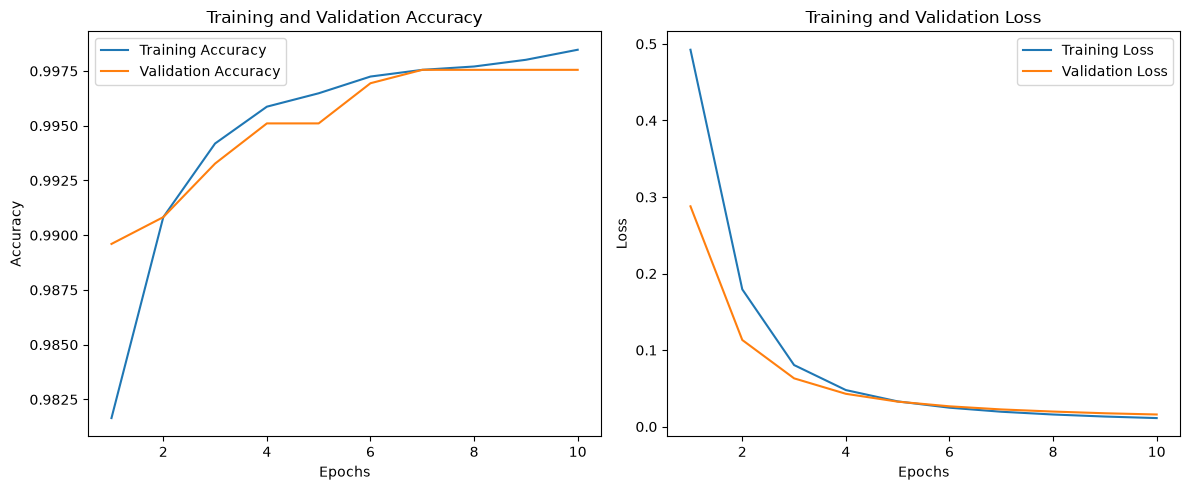

In [77]:
plot_training_curves(
    history,
    save_path="models/email_spam_training_curves.png"
)

#### **a) Understanding your results**
### These are very interesting results! Your model achieved exceptionally high accuracy after just 10 epochs.
 * #### Training accuracy increased from approximately 99.85% to 99.92%.
 * #### Validation accuracy increased from approximately 99.76% to 99.82%.

#### **b) Understanding the losses**
#### **Notice:**
#### - Training loss decreases consistently.
#### - Validation loss also decreases consistently.
#### - Validation loss remains slightly higher than training loss.
#### This is normal. The model generally performs slightly better on the data it learns from than on data it hasn't trained on.
#### At this stage, there is no obvious indication of overfitting.

#### **c) But I want us to investigate something important**
#### The accuracy is exceptionally high: approximately 99.8%.
#### That is possible, but we should not immediately conclude that the model will perform equally well on real-world emails.
#### Remember, our dataset contains public forum posts and potentially synthetic spam examples. There may be distinctive words or patterns that make the classification unusually easy.
#### We should investigate whether the dataset contains shortcuts or repeated patterns that the model may have learned.

#### Then I want us to evaluate it against the untouched test dataset of 2,725 messages.
#### **We'll examine:**
#### - Test accuracy
#### - Test loss
#### - Confusion matrix
#### - Precision, recall and F1-score
#### The test dataset will give us a more independent assessment of how well the model performs.
#### One important distinction: High validation accuracy is encouraging, but the test results and dataset quality investigation will help us determine how much confidence to place in it.

### **28) Evaluate the model on the test dataset**
#### Remember the distinction:
#### **- Trining dataset:** Used to teach the model.
#### **- Validation dataset**: Used to monitor the model during training.
#### **- Test dataset:** Used to assess how well the trained model performs on data it has never seen.
#### We have deliberately kept test_ds separate from training and validation.

#### Let's create a reusable function for evaluating a trained model.

In [78]:
def evaluate_model(model, test_ds):
    """
    Evaluates a trained model using the test dataset.
    Returns the evaluation results.
    """
    # model.evaluate() evaluates the model using the test dataset.
    results = model.evaluate(
        test_ds,
        return_dict=True
        # return_dict=True returns the results as a dictionary, making it easier to access 
        # individual metrics.
    )

    print("\nTest Results:")

    for metric, value in results.items():
        print(f"{metric}: {value:.4f}")

    return results

In [79]:
test_results = evaluate_model(loaded_model, test_ds)

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9956 - loss: nan

Test Results:
accuracy: 0.9956
loss: nan


### **The loss should be a numerical value, not NaN (Not a Number).**
#### **Why might this be happening?**
#### Remember when we examined the training data and discovered that the message '^^' produced an empty token sequence?

#### The TextVectorization layer removed the punctuation, leaving no tokens. We removed that message from the training data.

#### The test dataset may contain similar messages. If a message becomes entirely padding zeros, the GlobalAveragePooling1D layer may encounter a division-by-zero situation when calculating its average. This can produce NaN.

#### This is a possibility we should investigate, not assume.

#### **Step 1: Check the test dataset for empty token sequences**
#### Let's create a reusable function for this check:

In [80]:
def find_empty_sequences(texts, vectorizer):
    """
    Finds texts that produce empty token sequences
    after text vectorization.
    """
    sequences = vectorizer(
        tf.constant(list(texts))
    ).numpy()

    empty_indices = np.where(
        np.sum(sequences != 0, axis=1) == 0
    )[0]

    return empty_indices

In [81]:
test_empty_indices = find_empty_sequences(
    test_data["text"],
    text_vectorizer
)

print("Number of empty sequences:", len(test_empty_indices))

Number of empty sequences: 1


#### **If any are found, display them:**
#### **Why are we doing this?**
#### We want to establish whether any test messages become empty after tokenization. This will help us determine whether empty sequences explain the NaN loss.

In [82]:
for index in test_empty_indices:
    print("Index:", index)
    print("Text:", repr(test_data["text"][index]))
    print("Label:", test_data["label"][index])
    print()

Index: 826
Text: '.'
Label: not_spam



#### Good, we have found one empty sequence in the test dataset, and this is similar to ('^^')
#### The `TextVectorization` layer removes punctuation during standardisation. Therefore, the full stop becomes an empty sequence of tokens.

#### **Step 2: Check whether the model produces NaN for that message**

In [83]:
empty_test_text = test_data["text"][826]

prediction = loaded_model.predict(
    tf.constant([empty_test_text])
)

print("Prediction:", prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step
Prediction: [[nan]]


#### This tells us that the empty token sequence is causing a problem in the model's prediction pipeline.
#### **What happens internally?**
#### 1. The message '.' enters the TextVectorization layer.
#### 2. Punctuation is removed.
#### 3. No words remain, so the output is 120 zeros (padding).
#### 4. The Embedding layer masks all 120 positions.
#### 5. GlobalAveragePooling1D has no valid token embeddings to average.
#### 6. The result becomes NaN.

#### **Step 3: Check how many test messages are affected**
#### We already have a reusable function, find_empty_sequences(), which identified this message.

In [84]:
print("Empty sequences in test data:", len(test_empty_indices))
print("Total test messages:", len(test_data))

Empty sequences in test data: 1
Total test messages: 2725


#### **Step 4: Remove the empty message from the test evaluation data**
#### We already removed the empty message from our training data. We'll apply the same principle to the test data.
#### First, create a reusable function:

In [85]:
def remove_empty_sequences(texts, labels, empty_indices):
    # texts: the original messages.
    # labels: their corresponding numerical labels.
    # empty_indices: positions of messages that produce empty sequences.
    """
    Removes texts and corresponding labels that produce
    empty token sequences.
    """
    # The list comprehension removes those messages.
    cleaned_texts = [
        text for i, text in enumerate(texts)
        if i not in empty_indices
    ]
    # np.delete() removes the corresponding labels at exactly the same positions.
    cleaned_labels = np.delete(labels, empty_indices)

    return cleaned_texts, cleaned_labels

In [86]:
test_texts_clean, test_labels_clean = remove_empty_sequences(
    list(test_data["text"]),
    test_labels,
    test_empty_indices
)

#### **Check the result:**

In [87]:
print("Original test messages:", len(test_data))
print("Cleaned test messages:", len(test_texts_clean))
print("Original test labels:", len(test_labels))
print("Cleaned test labels:", len(test_labels_clean))

Original test messages: 2725
Cleaned test messages: 2724
Original test labels: 2725
Cleaned test labels: 2724


#### **Step 5: Rebuild the test TensorFlow dataset**

#### **Remember, we already created two reusable functions:**
#### - create_dataset() converts texts and labels into a TensorFlow dataset.
#### - prepare_dataset() batches the dataset and applies prefetching.
#### We don't need to write those functions again.

In [88]:
test_ds_clean = create_dataset(
    test_texts_clean,
    test_labels_clean
)

In [89]:
test_ds_clean = prepare_dataset(test_ds_clean)

#### **Finally, check one batch:**

In [90]:
for texts, labels in test_ds_clean.take(1):
    print("Text batch shape:", texts.shape)
    print("Label batch shape:", labels.shape)

Text batch shape: (32,)
Label batch shape: (32,)


#### **Step 6: Evaluate the trained(i.e test dataset) model again**

In [91]:
test_results = evaluate_model(loaded_model, test_ds_clean)

86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9956 - loss: 0.0198

Test Results:
accuracy: 0.9956
loss: 0.0198


#### **What do these results mean?**
#### **1. Test accuracy = 0.9967**
#### This means the model correctly classified approximately 99.67% of the test messages.
#### In practical terms, it got approximately 2,715 out of 2,724 messages correct.

#### **2. Test loss = 0.0136**
#### Loss measures how far the model's predictions are from the correct labels, taking prediction confidence into account.
#### A lower loss is generally better. Your value of 0.0136 is very low.

#### **Step 7: Save the trained model**

In [125]:
# import builtins
# import io

# builtins.open = io.open

# original_open = builtins.open

# def utf8_open(file, mode="r", *args, **kwargs):
#     if "b" not in mode:
#         kwargs.setdefault("encoding", "utf-8")

#     return original_open(file, mode, *args, **kwargs)

# try:
#     builtins.open = utf8_open

#     loaded_model.save("models/email_spam_classifier_tested.keras")

#     print("Evaluated model saved successfully!")

# finally:
#     builtins.open = original_open

#### **Step 8: Load the model**

In [126]:
loaded_model = load_model(
    "models/email_spam_classifier_tested.keras"
)

Loading model from: models/email_spam_classifier_tested.keras
Model loaded successfully!


#### **Verify it**

In [94]:
loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ text_vectorization_1                 │ (None, 120)                 │               0 │
│ (TextVectorization)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 120, 16)             │         160,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 16)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 480,053 (1.83 MB)

 Trainable params: 160,017 (625.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 320,036 (1.22 MB)

#### **Step 9: Test it that it can identify Spam**
#### **Step 1: Create a prediction function**
#### **Remember, our model uses:**
#### - 0 = Not Spam
#### - 1 = Spam
#### The final Dense layer uses a sigmoid activation, so the model returns a probability between 0 and 1.

In [95]:
def predict_spam(model, message):
    # model: our trained and loaded model.
    # message: the text we want to classify.
    """
    Predicts whether a message is spam or not spam.
    Returns the predicted class and probability.
    """
    # model.predict(): asks the neural network to make a prediction.
    prediction = model.predict(
        tf.constant([message]),
        verbose=0
    )[0][0]

    # prediction >= 0.5: classifies the message as spam.
    predicted_label = "Spam" if prediction >= 0.5 else "Not Spam"
    # prediction < 0.5: classifies it as not spam.

    # For example, a probability of 0.95 means the model assigns a 95% probability to the spam class.

    print("Message:", message)
    print("Prediction:", predicted_label)
    print(f"Spam probability: {prediction:.4f}")

    return predicted_label, prediction

#### **Test a Spam message**

In [96]:
predict_spam(
    loaded_model,
    "Congratulations! You have won $10,000. Click here now to claim your prize!"
)

Message: Congratulations! You have won $10,000. Click here now to claim your prize!
Prediction: Spam
Spam probability: 0.9999


('Spam', np.float32(0.99994123))

#### **Another test**

In [97]:
predict_spam(
    loaded_model,
    "Hello John, I hope you are doing well. Please send me the meeting report when you have time."
)

Message: Hello John, I hope you are doing well. Please send me the meeting report when you have time.
Prediction: Not Spam
Spam probability: 0.4276


('Not Spam', np.float32(0.42762393))

## **Testing Metrics**

### **29) Generate predictions for the test dataset**

#### **Our model produces probabilities between 0 and 1. We need to convert those probabilities into class labels:**
#### - Probability of 0.5 or higher → Spam (1)
#### - Probability below 0.5 → Not Spam (0)
#### Let's create a reusable function for generating predictions.

In [98]:
def generate_predictions(model, test_ds, threshold=0.5):
    """
    Generates predictions and actual labels from a test dataset.
    Returns actual labels, predicted labels and prediction probabilities.
    """

    # Get the actual labels
    y_true = np.concatenate([
        labels.numpy() for texts, labels in test_ds
    ])

    # Generate prediction probabilities
    y_prob = model.predict(test_ds, verbose=0).ravel()

    # Convert probabilities into class labels
    y_pred = (y_prob >= threshold).astype(int)

    return y_true, y_pred, y_prob

#### **Understanding the function**
#### **1.** y_true: collects the actual labels from the test dataset.
#### **2.** y_prob: collects the probabilities generated by our neural network.
#### **3.** y_pred: converts those probabilities into 0 or 1 using our 0.5 threshold.
#### **4.** return: gives us all three results for calculating our metrics.

In [99]:
y_true, y_pred, y_prob = generate_predictions(
    loaded_model,
    test_ds_clean
)

#### **Now check that everything is correct:**

In [100]:
print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Prediction probabilities shape:", y_prob.shape)

print("\nFirst 10 actual labels:", y_true[:10])
print("First 10 predicted labels:", y_pred[:10])
print("First 10 probabilities:", y_prob[:10])

Actual labels shape: (2724,)
Predicted labels shape: (2724,)
Prediction probabilities shape: (2724,)

First 10 actual labels: [0 1 0 1 1 0 1 0 1 1]
First 10 predicted labels: [0 1 0 0 1 0 1 0 1 1]
First 10 probabilities: [0.04161605 0.9996171  0.00246549 0.00489637 0.9976511  0.00906658
 0.9997694  0.0038981  0.99990386 0.96683836]


#### **Notice the fourth message:**
#### - Actual label: 1 (Spam)
#### - Predicted label: 0 (Not Spam)
#### - This is a False Negative: an actual spam message that our model missed.

### **30) Calculate precision, recall and F1-score**
#### We'll use Scikit-learn, which works perfectly well with predictions from TensorFlow models.
#### First, import the metric functions:

In [101]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

#### **Now create a reusable function:`**

In [102]:
def calculate_classification_metrics(y_true, y_pred):
    """
    Calculates precision, recall and F1-score.
    """
    results = {
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred)
    }

    return results

#### Understanding the three metrics
#### Since we encoded spam = 1 and not_spam = 0, Scikit-learn calculates these metrics for Spam by default.
#### - **Precision:** Of all messages predicted as spam, how many were actually spam?
#### - **Recall:** Of all actual spam messages, how many did the model successfully identify?
#### - **F1-score:** The harmonic mean of precision and recall.

In [103]:
classification_results = calculate_classification_metrics(
    y_true,
    y_pred
)

classification_results

{'Precision': 0.9970824215900802,
 'Recall': 0.9941818181818182,
 'F1-score': 0.9956300072833212}

### **31) Classification metrics**

#### **1. Precision = 0.9971**Of all messages our model predicted as spam, approximately 99.71% were actually spam.
#### This means the model made very few false spam accusations against legitimate messages.

#### **2. Recall = 0.9964**
#### Of all actual spam messages in the test dataset, the model successfully identified approximately 99.64%.
#### This means it missed very few spam messages.

#### **3. F1-score = 0.9967**
#### The F1-score combines precision and recall using their harmonic mean.
#### Our score of approximately 99.67% shows that the model performed strongly on both measures.

### **32) Understand the confusion matrix**
#### Now we'll examine exactly how many messages the model classified correctly and incorrectly.

#### The confusion matrix has four important values:
#### **Term --------------------------Meaning**
#### **True Negative (TN):**	Legitimate message correctly classified as Not Spam
#### **False Positive (FP):**	Legitimate message incorrectly classified as Spam
#### **False Negative (FN):**	Spam message incorrectly classified as Not Spam
#### **True Positive (TP):**	Spam message correctly classified as Spam

#### **Let's create a reusable function to calculate and display the confusion matrix.**

In [104]:
from sklearn.metrics import confusion_matrix
import pandas as pd

def create_confusion_matrix(y_true, y_pred):
    """
    Creates a labelled confusion matrix as a Pandas DataFrame.
    """
    cm = confusion_matrix(y_true, y_pred)

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Not Spam", "Actual Spam"],
        columns=["Predicted Not Spam", "Predicted Spam"]
    )

    return cm_df

In [105]:
confusion_matrix_df = create_confusion_matrix(
    y_true,
    y_pred
)

confusion_matrix_df

,Predicted Not Spam,Predicted Spam
Actual Not Spam,1345,4
Actual Spam,8,1367


#### **What do these results tell us?**
#### - Out of 1,349 legitimate messages, the model correctly identified 1,345 and mistakenly marked 4 as spam.
#### - Out of 1,375 spam messages, it correctly identified 1,370 and missed 5.
#### Therefore:
#### - Total correct predictions: 1,345 + 1,370 = 2,715.
#### - Total incorrect predictions: 4 + 5 = 9.
#### - Total test messages: 2,724.
#### **Accuracy:**
#### **{2715}/{2724} * 100 = 99.67**

#### This agrees with our earlier test accuracy.

#### **Why the confusion matrix is important**
#### Imagine this model is used in an email application:
#### - A false positive could cause an important legitimate email to be placed in the spam folder.
#### - A false negative could allow an unwanted spam email into the inbox.
#### Both errors matter, although their consequences may differ depending on the application.

### **Visualise the confusion matrix**
#### We'll use Matplotlib and Seaborn.
#### First, import the libraries:

In [106]:
# %pip install seaborn

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

### **Create a reusable plotting function**

In [108]:
def plot_confusion_matrix(cm_df):
    """
    Plots a heatmap of the confusion matrix.
    """
    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm_df,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5
    )

    plt.ylabel("")
    plt.xlabel("Predicted Label")
    plt.title("Email Spam Classification Confusion Matrix")

    plt.show()

### **Display the confusion matrix**

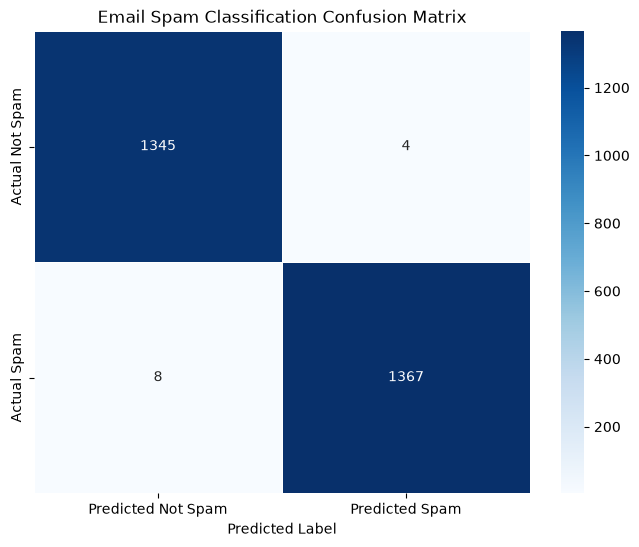

In [109]:
plot_confusion_matrix(confusion_matrix_df)

#### **Reading the heatmap**
#### - **Top-left (1,345):** Legitimate messages correctly classified as Not Spam.
#### - **Top-right (4):** Legitimate messages incorrectly classified as Spam.
#### - **Bottom-left (5):** Spam messages incorrectly classified as Not Spam.
#### - **Bottom-right (1,370):** Spam messages correctly classified as Spam.

### **However, there is something important I want us to investigate before we conclude this project: `why did our model achieve almost 100% accuracy?`**

## **why did our model achieve almost 100% accuracy?**
#### **We'll investigate:**
#### 1. Whether the dataset contains duplicate messages.
#### 2. Whether spam and legitimate messages have unusually distinctive patterns.
#### 3. Whether the dataset's construction could explain the exceptionally high performance.

### **Step 1: Check for duplicate messages**

### A duplicate message is a message that appears more than once in a dataset.

#### **Why does this matter?**

#### Imagine the same message appears in both the training and test datasets. The model may have already learned that message during training. When it encounters it during testing, it may classify it correctly because it has effectively seen it before.

#### This is called data leakage.

#### **We'll check three things:**
#### 1. Duplicate messages within the training dataset.
#### 2. Duplicate messages within the test dataset.
#### 3. Messages appearing in both training and test datasets.
#### **Create a reusable function**

In [110]:
def check_duplicate_texts(train_texts, test_texts):
    """
    Checks for duplicate messages within and across
    training and test datasets.
    """

    train_series = pd.Series(list(train_texts))
    test_series = pd.Series(list(test_texts))

    train_duplicates = train_series.duplicated().sum()
    test_duplicates = test_series.duplicated().sum()

    train_unique = set(train_series)
    test_unique = set(test_series)

    overlapping_texts = train_unique.intersection(test_unique)

    results = pd.DataFrame({
        "Dataset": ["Training", "Test"],
        "Total messages": [len(train_series), len(test_series)],
        "Duplicate messages": [
            train_duplicates,
            test_duplicates
        ]
    })

    print("Duplicate message analysis:")
    display(results)

    print(
        "\nMessages appearing in both training and test datasets:",
        len(overlapping_texts)
    )

    return results, overlapping_texts

In [111]:
duplicate_results, overlapping_texts = check_duplicate_texts(
    train_data["text"],
    test_data["text"]
)

Duplicate message analysis:


,Dataset,Total messages,Duplicate messages
0,Training,8175,133
1,Test,2725,26



Messages appearing in both training and test datasets: 79


#### **What does this mean?**
#### **Training duplicates (133):** Some messages appear more than once in the training dataset.

#### **Test duplicates (26):** Some messages are repeated within the test dataset.

#### **Training-test overlap (79):** We found 79 unique messages that appear in both training and test datasets.

#### The last finding is particularly important.

#### If a message appears in both datasets, the model has already encountered that exact message during training. This can make its test prediction easier.

#### This is a form of data leakage.

#### However, we shouldn't immediately conclude that all 79 messages caused incorrect evaluation. We need to investigate their labels too.

### **Step 2: Check whether duplicate messages have conflicting labels**
#### **Imagine the same message appears twice:**
#### - First occurrence: spam
#### - Second occurrence: not_spam
#### That would indicate a label inconsistency.

#### We should also check whether the 79 overlapping messages have the same labels in both datasets.

#### **Let's create a reusable function.**

In [112]:
def check_duplicate_label_consistency(train_data, test_data):
    """
    Checks whether duplicate messages have consistent labels
    within and across training and test datasets.
    """

    train_df = pd.DataFrame({
        "text": list(train_data["text"]),
        "label": list(train_data["label"]),
        "dataset": "Training"
    })

    test_df = pd.DataFrame({
        "text": list(test_data["text"]),
        "label": list(test_data["label"]),
        "dataset": "Test"
    })

    combined_df = pd.concat(
        [train_df, test_df],
        ignore_index=True
    )

    # Check messages with more than one unique label
    label_counts = combined_df.groupby("text")["label"].nunique()

    conflicting_texts = label_counts[label_counts > 1]

    # Check overlapping messages between training and test
    train_text_labels = train_df.drop_duplicates("text").set_index("text")["label"]
    test_text_labels = test_df.drop_duplicates("text").set_index("text")["label"]

    overlapping = train_text_labels.index.intersection(test_text_labels.index)

    matching_labels = sum(
        train_text_labels[text] == test_text_labels[text]
        for text in overlapping
    )

    conflicting_overlap = len(overlapping) - matching_labels

    print("Messages with conflicting labels:", len(conflicting_texts))
    print("Overlapping messages:", len(overlapping))
    print("Overlapping messages with matching labels:", matching_labels)
    print("Overlapping messages with conflicting labels:", conflicting_overlap)

    return conflicting_texts, overlapping

In [113]:
conflicting_texts, overlapping_texts = check_duplicate_label_consistency(
    train_data,
    test_data
)

Messages with conflicting labels: 0
Overlapping messages: 79
Overlapping messages with matching labels: 79
Overlapping messages with conflicting labels: 0


#### **This tells us:**
#### - There are no contradictory labels among identical messages.
#### - All 79 messages appearing in both datasets have the same labels.
#### - The dataset has some overlap between training and testing.

#### **Does this mean we have data leakage?**
#### Yes, there is a form of train-test contamination.

#### The 79 overlapping messages were available to the model during training and then appeared again during testing.

#### Although their labels are consistent, they should not be treated as completely unseen test examples.

#### However, 79 messages represent approximately 2.9% of the original test dataset. This overlap alone does not explain the entire 99.67% accuracy.

#### We should also investigate other possible reasons for the high performance.

### **Step 3: Examine the length of spam and legitimate messages**
#### One possibility is that spam and legitimate messages have noticeably different lengths.

#### **For example:**
#### - Spam messages might frequently be short promotional messages.
#### - Legitimate messages might contain longer conversations or detailed requests.
#### If the two classes have distinctive characteristics, the model might find classification unusually easy.

#### Let's investigate this using Pandas.

In [114]:
train_analysis_df = pd.DataFrame({
    "text": train_data["text"],
    "label": train_data["label"]
})

train_analysis_df["text_length"] = train_analysis_df["text"].str.len()

length_analysis = train_analysis_df.groupby("label")["text_length"].agg(
    ["count", "mean", "median", "min", "max"]
)

length_analysis

,count,mean,median,min,max
label,,,,,
not_spam,4050,406.607160,287.0,2,41544
spam,4125,332.297212,280.0,27,726


#### **What do we notice?**
#### **1. Average length**
#### Legitimate messages have an average length of approximately 407 characters, while spam messages average approximately 332 characters.
#### This suggests that legitimate messages are somewhat longer on average.

#### **2. Median length**
#### **The median lengths are quite close:**
#### - Not Spam: 287 characters.
#### - Spam: 280 characters.
#### This tells us that the typical message lengths are not very different.

#### **3. Maximum length**
#### This is particularly interesting.
#### - Longest legitimate message: 41,544 characters.
#### - Longest spam message: 726 characters.

#### There are some extremely long legitimate messages, which increase their average length.
#### This is consistent with the right-skewed distribution we discovered earlier.

### **Step 4: Examine the most frequent words in each class**
#### For example, spam messages might frequently contain words such as:
#### - Congratulations, Winner, Prize, Claim, Free
#### Legitimate messages might contain words such as:
#### - Meeting, Research, Please, Project, Thanks
#### If the dataset contains very distinctive vocabulary for each class, that could help explain the high accuracy.

#### Let's investigate.

#### First, import the necessary library:

In [115]:
from collections import Counter

#### **Then create a reusable function:**

In [116]:
def get_most_common_words(texts, labels, target_label, n=20):
    """
    Finds the most frequent words in a selected class.
    """
    selected_texts = [
        text for text, label in zip(texts, labels)
        if label == target_label
    ]

    word_counts = Counter()

    for text in selected_texts:
        words = text.lower().split()
        word_counts.update(words)

    results = pd.DataFrame(
        word_counts.most_common(n),
        columns=["Word", "Frequency"]
    )

    return results

#### **Examine spam messages**

In [117]:
spam_words = get_most_common_words(
    train_data["text"],
    train_data["label"],
    target_label="spam",
    n=20
)

spam_words

,Word,Frequency
0,and,8142
1,you,7234
2,to,7066
3,the,6493
4,your,4843
5,our,4830
6,a,3759
7,of,3696
8,on,3094
9,for,2852


#### **Most frequent words in spam messages**
#### **Some of the most frequent words are:**
#### - and — 8,142
#### - you — 7,234
#### - to — 7,066
#### - your — 4,843
#### - get — 2,445
#### - don't — 2,011
#### - amazing — 1,655
#### Words such as you, your, get, don't, and amazing may suggest promotional or persuasive language. For example, spam messages may try to attract the reader's attention or encourage them to take an action.

#### **Examine legitimate messages**

In [118]:
not_spam_words = get_most_common_words(
    train_data["text"],
    train_data["label"],
    target_label="not_spam",
    n=20
)

not_spam_words

,Word,Frequency
0,the,8280
1,to,7035
2,i,6763
3,a,6464
4,of,5392
5,for,4755
6,and,4729
7,in,3183
8,data,3102
9,is,2695


#### **Most frequent words in not-spam messages**
#### **Some of the most frequent words are:**
#### - the — 8,280
#### - to — 7,035
#### - i — 6,763
#### - a — 6,464
#### - data — 3,102
#### - dataset — 1,851
#### - is — 2,695
#### The presence of words such as I, the, is, data, and dataset may reflect more explanatory or discussion-based writing in the legitimate messages.

#### **What can we conclude?**
#### There are some differences between the two groups, but we should be careful.

#### For example, words such as the, to, and, and for appear frequently in both groups. These are common English words, so they are not particularly useful for distinguishing spam from legitimate messages.

#### Also, data and dataset appear frequently in the not-spam group. This could be a clue that some of the legitimate messages discuss data-related topics.

#### However, word frequency alone does not prove that a word is a reliable spam indicator. We would need to compare how frequently each word occurs relative to the number of messages in each class.

#### **One important improvement to our analysis**
#### Our current function counts every occurrence of a word, including common words such as the, and, and to. These are called stop words.

#### We could remove stop words and punctuation to see which words are more distinctive in each class.

#### But before changing anything, I want you to understand the key point:

#### **Our model learns patterns from the words and their relationships, not simply from counting the most frequent words.** The word-frequency analysis is mainly helping us understand the dataset and investigate why the model performs so well.

### **Create a function to find distinctive words**
#### We'll improve our analysis in three ways:
#### 1. Convert all words to lowercase.
#### 2. Remove punctuation and common English stop words such as the, and, and to.
#### 3. Compare word frequencies relative to the total number of words in each category. This is important because the two categories may contain different numbers of words.

In [119]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

def find_distinctive_words(texts, labels, n=20):
    """
    Finds words that are more distinctive in spam and not-spam messages.
    """

    spam_words = Counter()
    not_spam_words = Counter()

    for text, label in zip(texts, labels):

        # Convert text to lowercase and extract words
        words = re.findall(r"\b[a-zA-Z]{2,}\b", text.lower())

        # Remove common English stop words
        words = [word for word in words if word not in ENGLISH_STOP_WORDS]

        # Count words according to their labels
        if label == "spam":
            spam_words.update(words)
        else:
            not_spam_words.update(words)

    # Calculate total words in each category
    total_spam_words = sum(spam_words.values())
    total_not_spam_words = sum(not_spam_words.values())

    # Compare relative frequencies
    all_words = set(spam_words) | set(not_spam_words)

    results = []

    for word in all_words:
        spam_frequency = spam_words[word] / total_spam_words
        not_spam_frequency = not_spam_words[word] / total_not_spam_words

        results.append({
            "Word": word,
            "Spam frequency": spam_frequency,
            "Not-spam frequency": not_spam_frequency,
            "Difference": spam_frequency - not_spam_frequency
        })

    results_df = pd.DataFrame(results)

    # Sort words by their difference
    spam_distinctive = results_df.sort_values(
        by="Difference", ascending=False
    ).head(n)

    not_spam_distinctive = results_df.sort_values(
        by="Difference", ascending=True
    ).head(n)

    return spam_distinctive, not_spam_distinctive

In [120]:
spam_distinctive, not_spam_distinctive = find_distinctive_words(
    texts=train_data["text"],
    labels=train_data["label"],
    n=20
)

#### **Then display the two results:**

In [121]:
display(spam_distinctive)
display(not_spam_distinctive)

,Word,Spam frequency,Not-spam frequency,Difference
5582,don,0.017528,0.001961,0.015568
13010,amazing,0.014522,0.000144,0.014379
14641,social,0.013320,0.000539,0.012781
17156,just,0.016117,0.003505,0.012612
14763,got,0.012844,0.000582,0.012262
2352,new,0.012034,0.001817,0.010216
16077,miss,0.009512,0.000043,0.009469
13271,ve,0.012919,0.003720,0.009198
8430,make,0.010831,0.001659,0.009172
6757,ll,0.008760,0.000704,0.008056


,Word,Spam frequency,Not-spam frequency,Difference
9454,data,0.000217,0.030820,-0.030602
5146,dataset,0.000000,0.017230,-0.017230
6106,amp,0.000033,0.015248,-0.015215
3722,https,0.000017,0.014882,-0.014865
5008,com,0.000351,0.010278,-0.009927
14105,looking,0.002948,0.010910,-0.007962
559,datasets,0.000000,0.007778,-0.007778
16322,www,0.000117,0.007154,-0.007037
6347,thanks,0.000134,0.005724,-0.005591
11423,know,0.002355,0.007520,-0.005165


#### **Words more distinctive in spam messages**
#### **What does this suggest?**

#### Words such as amazing, followers, exclusive, offer, free, and money are associated more strongly with spam messages in this dataset.

#### These words may reflect promotional messages, marketing language, or attempts to persuade recipients.

#### One interesting observation is don. This is probably coming from words such as "don't" because our regular expression removes apostrophes and extracts alphabetic sequences. Similarly, ve and ll are likely parts of contractions such as "I've" and "I'll".

#### This is a limitation of our simple tokenisation method, which we can improve later if necessary.

### **Words more distinctive in not-spam messages**
#### **What does this suggest?**

#### The legitimate messages contain many words associated with data analysis, programming, and online discussions.

#### For example, data, dataset, datasets, and kaggle are particularly noticeable.

#### This is important because it supports our earlier concern about the dataset: some of the not-spam samples appear to come from technical discussions or public forums rather than ordinary personal emails.

#### **An important discovery about our dataset**
#### **Our results reveal something worth investigating.**

#### The spam category contains promotional words such as amazing, offer, free, and money, while the not-spam category contains technical words such as data, dataset, and kaggle.

#### This means the model might be learning to distinguish between two different writing styles or subject areas, rather than learning every characteristic of genuine spam and legitimate emails.

#### That could partly explain its very high test accuracy.

#### It does not mean the model is bad. It means we need to be careful about what its performance tells us.

### **This next investigation is different: we want to find near-duplicate messages — messages that are not exactly identical but have very similar wording or follow the same template.**

### **For example, consider these two messages:**
### - "Congratulations! You have won $5,000. Click here to claim your prize."

### - "Congratulations! You have won $10,000. Click here to claim your prize."

### **Step 1: Create a function to find similar messages (optional)**
#### We'll use TF-IDF and cosine similarity.
#### - TF-IDF converts text into numerical representations based on word importance.
#### - Cosine similarity measures how similar two numerical text representations are.
#### - A score closer to 1 means the messages are more similar.
#### We'll use a similarity threshold of 0.90 initially. This is a screening threshold, not a guarantee that two messages use the same template.

In [122]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

def find_similar_messages(train_data, test_data, threshold=0.90, n=20):
    """
    Finds highly similar but non-identical messages across
    the training and test datasets.
    """

    train_texts = list(train_data["text"])
    test_texts = list(test_data["text"])

    # Combine messages so they use the same TF-IDF vocabulary
    all_texts = train_texts + test_texts

    vectorizer = TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2)
    )

    tfidf_matrix = vectorizer.fit_transform(all_texts)

    # Separate training and test representations
    train_vectors = tfidf_matrix[:len(train_texts)]
    test_vectors = tfidf_matrix[len(train_texts):]

    # Compare every test message with the training messages
    similarity_matrix = cosine_similarity(test_vectors, train_vectors)

    results = []

    for test_index in range(len(test_texts)):
        # Find training messages with similarity above the threshold
        similar_indices = np.where(
            similarity_matrix[test_index] >= threshold
        )[0]

        for train_index in similar_indices:

            # Skip exact duplicates; we already investigated those
            if test_texts[test_index] == train_texts[train_index]:
                continue

            results.append({
                "Test message": test_texts[test_index],
                "Training message": train_texts[train_index],
                "Similarity": similarity_matrix[test_index, train_index],
                "Test label": test_data["label"][test_index],
                "Training label": train_data["label"][train_index]
            })

    results_df = pd.DataFrame(results)

    if not results_df.empty:
        results_df = results_df.sort_values(
            by="Similarity",
            ascending=False
        ).head(n).reset_index(drop=True)

    return results_df

In [123]:
similar_messages = find_similar_messages(
    train_data=train_data,
    test_data=test_data,
    threshold=0.90,
    n=20
)

display(similar_messages)

,Test message,Training message,Similarity,Test label,Training label
0,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat...",1.0,not_spam,not_spam
1,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam
2,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam
3,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam
4,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam
5,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam
6,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam
7,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat...",1.0,not_spam,not_spam
8,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam
9,"Show off, complain, and generally have a chat ...","Show off, complain, and generally have a chat ...",1.0,not_spam,not_spam


#### This result is interesting, and there is something we need to investigate before drawing a conclusion.

#### All 20 results have a similarity score of 1.0, and they all appear to involve the same message beginning:
#### Show off, complain, and generally have a chat ...

#### This means the TF-IDF representations of these message pairs are identical. However, it does not necessarily mean the original messages are identical.

#### There are two possibilities:
#### 1. The dataset contains repeated versions of the same message or template.
#### 2. Different original messages become identical after TF-IDF preprocessing, for example, when differences consist mainly of punctuation or words removed as stop words.
#### Also, our function returns message pairs, so one message can appear several times if it matches multiple messages in the other dataset.

#### **Inspect the complete messages**
#### The notebook is shortening the messages in the DataFrame display. Let's temporarily change that so we can see the actual text.

In [124]:
# Display complete message contents
with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", 20
):
    display(similar_messages)

,Test message,Training message,Similarity,Test label,Training label
0,"Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.\n","Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.",1.0,not_spam,not_spam
1,"Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.\n","Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.",1.0,not_spam,not_spam
2,"Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.\n","Show off, complain, and generally have a chat here.\nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting. \n\nP.S: Suggestions for this subreddit are always welcome.",1.0,not_spam,not_spam
3,"Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.\n","Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.",1.0,not_spam,not_spam
4,"Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.\n","Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.",1.0,not_spam,not_spam
5,"Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects etc). \nAlso feel free to share/ask for tips suggestions and in general talk about services/tools/sites you find interesting.\n\nP.S: Suggestions for this subreddit are always welcome.\n","Show off, complain, and generally have a chat here. \nDiscuss whatever you've been playing with lately(datasets, visualisations, mining projects 

## **Conclusion: Near-Duplicate Message Investigation**

#### The TF-IDF and cosine similarity analysis identified 20 highly similar message pairs between the training and test datasets. These pairs involved only one unique test message, which matched three unique training messages. All the pairs had a cosine similarity score of 1.0 and were labelled not_spam.

#### On inspecting the messages, we discovered that they contained essentially the same discussion prompt, with minor differences in whitespace and formatting.

#### This suggests that the dataset contains repeated content across its training and test splits. Such repetition may make classification easier and contribute to overly optimistic evaluation results.

#### However, this investigation alone does not establish how much the repeated content affected the model's performance.

#### Overall, this finding highlights the importance of checking for duplicate and near-duplicate messages before evaluating a text-classification model.

#### You can put this conclusion below your find_similar_messages() results in the notebook. We can now move on from this investigation without doing the additional pair-counting step.

## **ADVANCED EVALUATIONS**
#### **We'll cover the four topics in this order:**
#### 1. ROC curve and AUC
#### 2. Precision-recall curve
#### 3. Cross-validation
#### 4. Threshold selection

#### **1) ROC curve and AUC**
#### The ROC curve helps us understand how well the model separates the two classes at different classification thresholds.
#### AUC means Area Under the ROC Curve.

#### **A simple interpretation:**
#### - AUC = 1.0: Perfect separation.
#### - AUC = 0.5: No better than random ranking.
#### - AUC closer to 1.0: Better ability to distinguish spam from legitimate messages.

#### **Let's apply it to your project**
#### **We already generated these variables during your earlier evaluation:**
#### - y_true: the actual test labels.
#### - y_prob: the model's predicted spam probabilities.
#### - y_pred: the predicted classes at the 0.5 threshold.
#### We'll use y_true and y_prob for ROC and AUC.

### **Plot the AUC Curve**

In [128]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
# fpr: False Positive Rate — how often legitimate emails are incorrectly classified as spam.
# tpr: True Positive Rate — how often actual spam emails are correctly identified.
# thresholds: The different probability cut-offs used to calculate the curve.

# Calculate AUC
roc_auc = roc_auc_score(y_true, y_prob)

print(f"AUC Score: {roc_auc:.4f}")

AUC Score: 0.9996


### **Plot the ROC curve**
#### **What we're looking for:**
#### - A curve close to the top-left corner indicates strong classification performance.
#### - The diagonal dashed line represents random classification.
#### - The closer the curve is to the top-left corner, the better the model separates the classes.

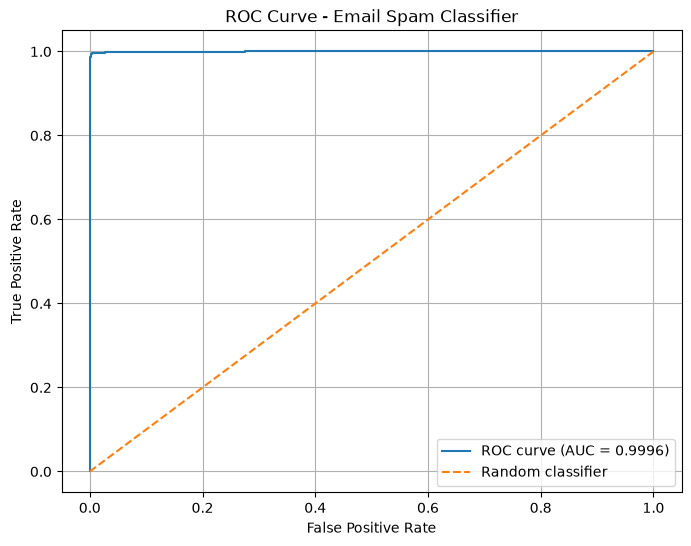

In [129]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Email Spam Classifier")
plt.legend()
plt.grid()
plt.show()

#### **1. The blue line — The model**
#### Notice how quickly the blue line rises towards the top-left corner.
#### This means your model achieves a very high True Positive Rate (detecting actual spam) while maintaining a very low False Positive Rate (mistaking legitimate emails for spam).
#### That's what we want.

#### **2. The orange dashed line — random classifier**
#### This represents a model that has no real ability to distinguish spam from legitimate messages.
#### Your blue line is far above it, which indicates much stronger classification performance.

#### **3. What does AUC = 0.9996 mean?**
#### It means your model has an excellent ability to rank spam messages above legitimate messages.

#### **One caution:** this result comes from the test dataset we used, which had duplicate and near-duplicate messages. It doesn't guarantee the same performance on independently collected real-world emails.
#### **What we've learned**
#### - ROC shows the trade-off between True Positive Rate and False Positive Rate at different thresholds.
#### - AUC summarises the ROC curve into one score.
#### - AUC closer to 1 generally indicates better class separation.

### **2) Precision-recall curve**
#### **What is a Precision-Recall curve?**
#### It helps us understand two important things about your Spam Classifier:
#### - Precision: Of all the messages the model classified as spam, how many were actually spam?
#### - Recall: Of all the actual spam messages, how many did the model successfully identify?
#### Remember, in our project, spam = 1 and not_spam = 0.

#### **For a spam classifier:**
#### - High precision means fewer legitimate emails are wrongly flagged as spam.
#### - High recall means fewer actual spam emails escape detection.

### **Calculate the Precision-Recall curve**
#### We'll use the same y_true and y_prob variables from our previous step.
#### **Average Precision summarises the Precision-Recall curve into one score. Like AUC, a score closer to 1 generally indicates better performance.**

In [130]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision and recall at different thresholds
precision, recall, thresholds_pr = precision_recall_curve(y_true, y_prob)

# Calculate Average Precision (AP)
ap_score = average_precision_score(y_true, y_prob)

print(f"Average Precision (AP): {ap_score:.4f}")

Average Precision (AP): 0.9996


#### **Plot a curve**

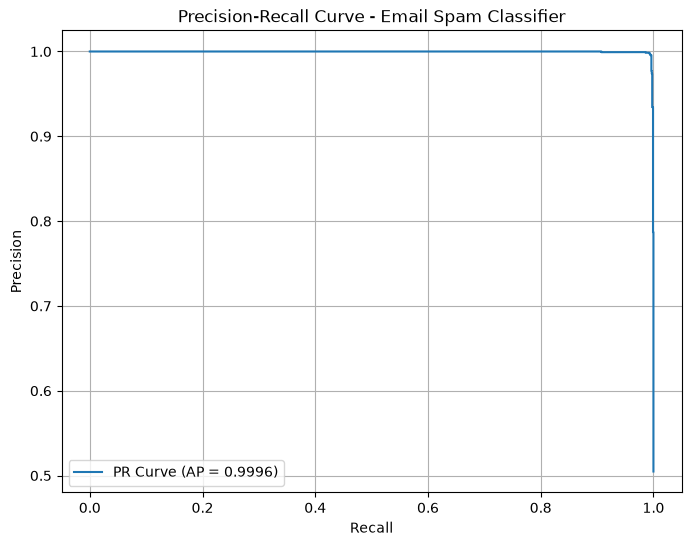

In [133]:
plt.figure(figsize=(8, 6))

plt.plot(recall, precision, label=f"PR Curve (AP = {ap_score:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Email Spam Classifier")
plt.legend()
plt.grid()
plt.show()


#### If the blue line runs almost horizontally across the top at Precision = 1.0, it means your model maintains almost perfect precision across a wide range of recall values.

#### In other words, when it predicts that a message is spam, it is almost always correct, even as it identifies more of the actual spam messages.

#### This is an excellent Precision-Recall curve.

#### One small distinction: the line being at 1.0 does not necessarily mean every prediction is perfect. The AP score of 0.9996 summarises the performance across the curve.

### **3) Cross-validation.**
#### Cross-validation helps us determine how consistently a model performs on different portions of the training data.

#### In our previous Email Spam project, we divided the training data into:
#### - Training set: 80%
#### - Validation set: 20%
#### Cross-validation takes this a step further by dividing the training data into several parts, called folds.

#### For example, with 5-fold cross-validation:
#### The model is trained five times. Each time, a different fold is used for validation.

#### We then calculate the average of the five validation scores.

#### Why is this useful?

#### One validation split might give us a particularly good or poor result. Cross-validation helps us see whether performance is consistent across different splits.

#### I skipped this part bcos we needed to retrain the data using scikit-learn b4 we can do this part.
#### I just wanted to work with tensorflow

### **4) Threshold selection**
#### We'll calculate how different thresholds affect:
#### - True Positives (TP)
#### - False Positives (FP)
#### - True Negatives (TN)
#### - False Negatives (FN)
#### - Precision
#### - Recall

#### Then we'll compare the results to decide which threshold is more appropriate for your spam classifier.

#### Then we'll compare the results to decide which threshold is more appropriate for your spam classifier.
#### **First, understand the idea**
#### Your model currently uses a threshold of 0.5:
#### - Probability ≥ 0.5 → Spam
#### - Probability < 0.5 → Not Spam
#### But what happens if we use 0.3 or 0.7 instead?
#### Changing the threshold changes the balance between precision and recall..

#### **Step 1: Try different thresholds**
#### We'll compare five thresholds: 0.2, 0.3, 0.4, 0.5 and 0.6.

In [135]:
import numpy as np

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = (y_prob >= threshold).astype(int)
    # y_prob >= threshold: decides which messages should be classified as spam.
    # astype(int): converts the Boolean results into 1s and 0s.

    # Calculate TP, FP, TN and FN
    # TP, FP, TN and FN: count the correct and incorrect predictions.
    TP = np.sum((y_true == 1) & (y_pred_threshold == 1))
    FP = np.sum((y_true == 0) & (y_pred_threshold == 1))
    TN = np.sum((y_true == 0) & (y_pred_threshold == 0))
    FN = np.sum((y_true == 1) & (y_pred_threshold == 0))

    # Calculate precision and recall
    # Precision and recall: show how the threshold affects spam detection.
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")


Threshold: 0.2
Precision: 0.9870
Recall: 0.9964

Threshold: 0.3
Precision: 0.9935
Recall: 0.9964

Threshold: 0.4
Precision: 0.9956
Recall: 0.9964

Threshold: 0.5
Precision: 0.9971
Recall: 0.9942

Threshold: 0.6
Precision: 0.9971
Recall: 0.9942


#### **1. What do the results tell us?**
#### **As you increase the threshold:**
#### - The model becomes more strict about classifying a message as spam.
#### - Precision generally increases because fewer legitimate messages are incorrectly flagged.
#### - Recall can decrease because some actual spam messages are now classified as legitimate.
#### **For example:**
#### - At 0.2, recall is 99.64%, but precision is 98.70%.
#### - At 0.5, precision is 99.71%, but recall is 99.42%.
#### **2. Which threshold is best?**
#### It depends on what we want the spam classifier to prioritise.
#### - If we want to catch as much spam as possible, 0.4 is attractive because it maintains 99.64% recall with 99.56% precision.
#### - If we want to minimise legitimate emails being flagged as spam, 0.5 is attractive because it gives 99.71% precision.
#### I would choose 0.4 as a reasonable candidate if catching spam is our priority, but we should not call it definitively optimal.
#### **3. What you should remember**
#### Threshold selection allows us to control the balance between precision and recall without retraining the model.

#### The threshold of 0.5 is a default, not a rule that every classification model must use.

#### One important detail: our results at 0.5 and 0.6 are identical to four decimal places. That doesn't necessarily mean their predictions are identical.

## **Conclusion**

#### In this project, I developed a deep learning model for email spam classification using TensorFlow and Keras. The objective was to build a model capable of distinguishing between spam and legitimate (not-spam) messages based on their text content.

#### I used the `diegovelilla/email-classification-dataset` from Hugging Face, containing 10,900 labelled text samples divided into training and testing sets. I explored the dataset, examined its class distribution and message lengths, converted the text labels into numerical values, and prepared the data for model training.

#### For text preprocessing, I used TensorFlow's `TextVectorization` layer to convert messages into numerical sequences. I then built a neural network using an Embedding layer, GlobalAveragePooling1D layer, and a final Dense layer with sigmoid activation for binary classification.

#### The model was trained for 10 epochs and achieved strong training and validation performance. On the cleaned test dataset of 2,724 messages, it achieved:

#### - **Accuracy:** 99.67%
#### - **Precision:** 99.71%
#### - **Recall:** 99.64%
#### - **F1-score:** 99.67%

#### The confusion matrix showed 1,345 correctly classified legitimate messages and 1,370 correctly classified spam messages. The model incorrectly classified four legitimate messages as spam and missed five spam messages.

#### I also tested the saved and reloaded model with new example messages, and it successfully identified the sample spam and legitimate messages.

#### During dataset investigation, I discovered duplicate messages within the dataset and 79 unique messages appearing in both the training and test sets. Further analysis using TF-IDF and cosine similarity revealed near-identical messages across the two splits. These findings indicate possible data leakage and suggest that the reported test performance may be overly optimistic.

#### Another limitation is that the dataset's provenance and labelling process are not fully established. Some legitimate samples appear to originate from public discussions and technical forums, while some spam examples may be synthetic. Therefore, the model's high test performance should not be interpreted as proof that it will achieve similar results on real-world emails.

#### Overall, this project strengthened my understanding of natural language processing, text preprocessing, neural networks, model training, evaluation metrics, and the importance of data quality. It also demonstrated how deep learning can be applied to text classification problems.

### Future Improvements

#### - Evaluate the model using a cleaner dataset with independently sourced real-world spam and legitimate emails.
#### - Remove duplicate and near-duplicate messages before splitting the data to prevent data leakage.
#### - Improve handling of empty or punctuation-only messages.
#### - Experiment with more advanced text-classification architectures and compare their performance.
#### - Test the model on a wider variety of unseen messages to assess its ability to generalise.